In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Statistical Analysis of Production Cycles (MC15 eKW 1150/12500 Hybrid – 45-liter box)

Data from the injection molding machine sensors, recorded over 24 cycles, indicate a high level of stability; however, detailed statistical control reveals specific deviations that pose a risk of producing defective components.

### 1. Statistical Profile of the Production Process

Based on the sample, the key parameters regarding heat exchange and injection dynamics show the following average values ​​and stability levels:

*   **Filling time:** Stable at approximately **0.90 seconds**. The overall spread is minimal (ranging from 0.89 to 0.91 sec), indicating a consistent injection speed.
*   **Pressure peak:** The average value is **121.78 bar**. The narrow range of variation demonstrates homogeneity and stable viscosity of the polypropylene melt.
*   **Cushion position:** An average value of **12.55 mm**. Maintaining a stable cushion at the end of the dosing phase ensures that the hold-on pressure is transmitted effectively, preventing the formation of sink marks and volumetric shrinkage. ### 2. Identified Anomalies and Technological Risk

Mathematical analysis has identified three specific cycles that fall outside the bounds of a normal statistical distribution and carry a risk of producing defective parts:

#### Cycle 17928 — High Risk of Geometric Defect (Overfilling)
*   **Observed Deviation:** The highest peak pressure (**122.40 bar**) and maximum screw torque (**1004 Nm**) were recorded, along with a significant deviation in the initial plasticization position (**14.0 mm** vs. an average of 12.68 mm).
*   **Impact on Quality:** Excessive pressure and material volume within the cavity can lead to **mold overfilling (flash)**—the formation of plastic burrs along the tool parting lines—or the box exceeding its target weight.

#### Cycle 17919 — Risk of Underfilling or Voids
*   **Observed Deviation:** The initial dosing pressure drops sharply to **47.40 bar** (compared to a normal value of ~51.70 bar), and the residual cushion decreases to the critical minimum for this production run—**11.60 mm**.
*   **Impact on Quality:** There is a risk of air entrapment within the cavity, which can result in surface marks, **internal voids**, or incomplete filling in the furthest sections of the part. #### Cycle 17937 — Slight Kinematic Deviation
*   **Recorded Deviation:** The switch-over position to holding pressure (*Switch-over position*) dropped to **52.90 mm** (compared to a fixed value of 53.00 mm in all other cycles).


### 3. Conclusion and Assessment of Defect Probability

*   **Process Capability:** The production line demonstrates a stability level of **91.6%** (22 out of 24 cycles fall within perfect statistical limits).
*   **Probability of Defective Output:** The mathematical probability of a defective part in this batch is estimated at **~8.3%**, specifically concerning cycles **17928** and **17919**.

In [6]:
df = pd.read_csv("data/mc15.csv")
# Премахване на средните стойности изчиляване на статистическите показатели
df_cycles = df[df['Cycle No.'] != 'Average'].copy()
for col in df_cycles.columns:
    if col != 'Cycle No.':
        df_cycles[col] = pd.to_numeric(df_cycles[col])
summary = df_cycles.describe().T[['mean', 'std', 'min', 'max']]
print(summary.to_string())

# Проверете за аномалии или отклоняващи се стойности
outliers_list = []
for col in df_cycles.columns:
    if col != 'Cycle No.':
        m = df_cycles[col].mean()
        s = df_cycles[col].std()
        if s > 0:
            out_count = ((df_stats := df_cycles[col]) < m - 3*s) | (df_stats > m + 3*s)
            if out_count.sum() > 0:
                anomalies = df_cycles.loc[out_count, ['Cycle No.', col]]
                for _, row in anomalies.iterrows():
                    outliers_list.append({
                        "Параметър": col,
                        "Номер на цикъл": int(float(row['Cycle No.'])),
                        "Измерена стойност": row[col]
                    })
if outliers_list:
    df_outliers = pd.DataFrame(outliers_list)
    print("\nОТКРИТИ АНОМАЛИИ В ПРОЦЕСА:")
    display(df_outliers.style.hide(axis="index"))
else:
    print("\nНяма открити аномалии извън 3-sigma границите.")




                                         mean        std     min      max
Filling time (s)                     0.904167   0.009286    0.89     0.91
Hold-on pressure (bar)              55.083333   0.038069   55.00    55.10
Switch-over position (mm)           52.995833   0.020412   52.90    53.00
Switch-over pressure (bar)         121.841667   0.230154  121.50   122.50
Injection start position (mm)      214.279167   0.241335  213.90   214.80
Pressure peak position (mm)         54.170833   0.227423   53.90    54.60
Pressure peak (bar)                121.779167   0.232153  121.40   122.40
Cushion position (mm)               12.545833   0.395605   11.60    13.50
Cushion minimum position (mm)       12.420833   0.418048   11.40    13.40
Plasticising time (s)               14.950833   0.317708   14.47    15.66
Plasticising position (mm)         200.095833   0.157367  199.80   200.30
Backpressure (bar)                   9.662500   0.049454    9.60     9.70
Rotation speed (rpm)               250

Параметър,Номер на цикъл,Измерена стойност
Switch-over position (mm),17937,52.900000
Plasticising start position (mm),17928,14.000000
Plasticising start pressure (bar),17928,47.400000
Plasticising start pressure (bar),17919,47.400000


### Description of Statistical Indicators (Process Metrics)

The following four descriptive statistical indicators are used to evaluate the stability of the machine in the production of the 45-liter container:

1. **Mean (`mean`):** Defines the process center. It represents the arithmetic average level around which the parameters fluctuate.
2. **Standard Deviation (`std`):** Measures the dispersion of the data. It serves as a direct indicator of the injection molding machine's stability—a lower value signifies higher repeatability across individual production cycles.
3. **Minimum Value (`min`):** The lowest recorded data point for a parameter within the sample, defining the lower limit of the actual distribution.
4. **Maximum Value (`max`):** The highest recorded data point for a parameter, reflecting the peaks and maximum loads within the system.

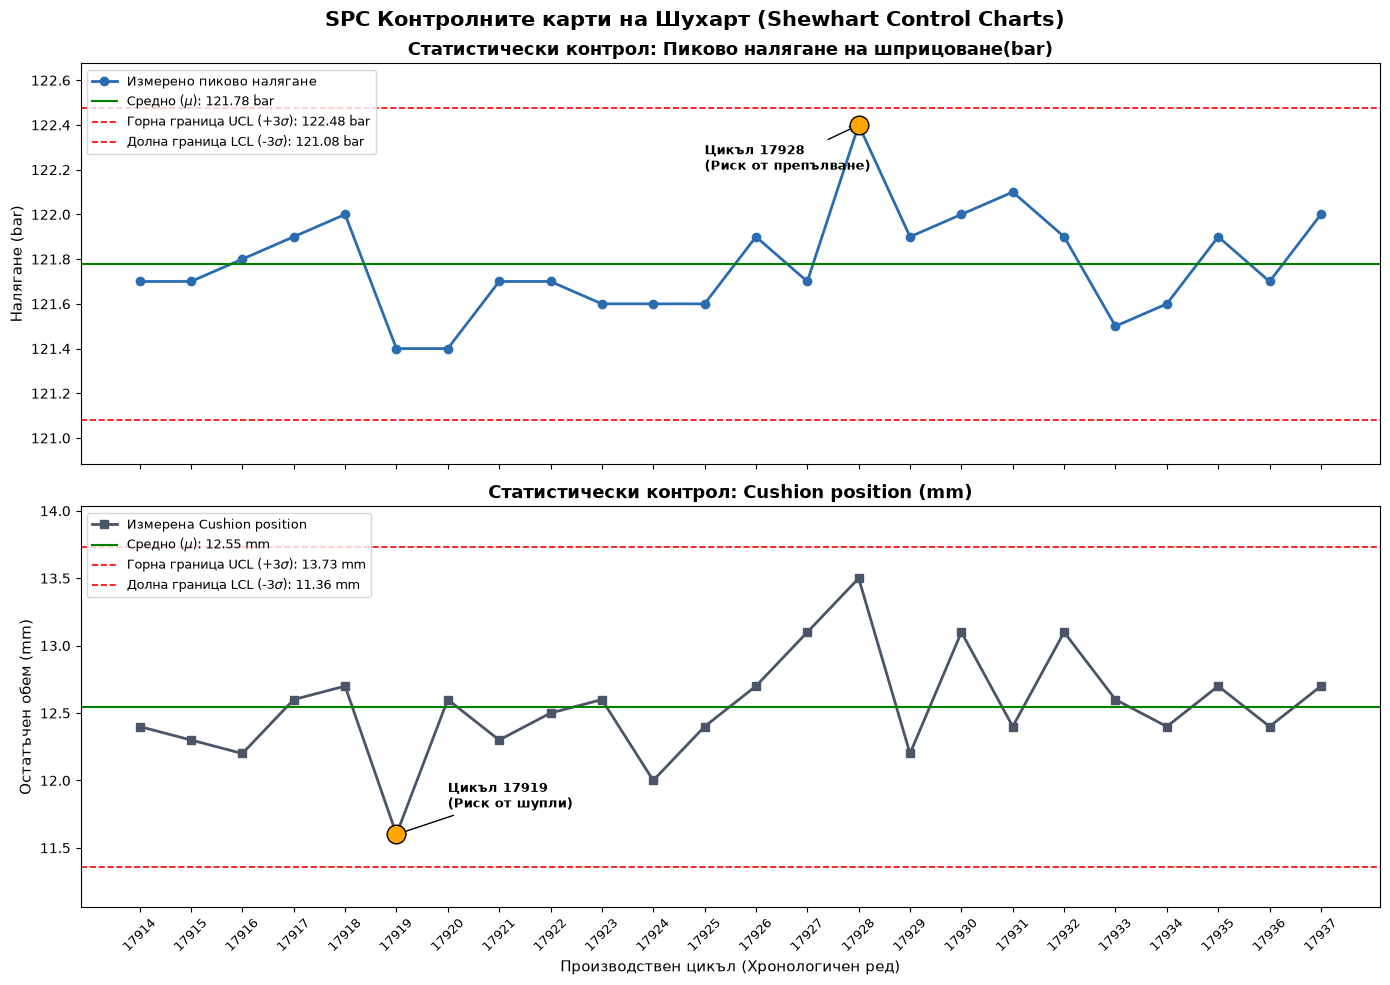

In [7]:
df_clean = df[df['Cycle No.'] != 'Average'].copy()
df_clean = df_clean.dropna(subset=['Cycle No.'])
df_clean['Cycle No.'] = df_clean['Cycle No.'].astype(int)
df_clean = df_clean.sort_values('Cycle No.').reset_index(drop=True)


fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

x_indices = np.arange(len(df_clean))
cycles_str = df_clean['Cycle No.'].astype(str)

# =====================================================================
# КАРТА 1: ПИКОВО НАЛЯГАНЕ (Pressure Peak Chart)
# =====================================================================
p_mean = df_clean['Pressure peak (bar)'].mean()
p_std = df_clean['Pressure peak (bar)'].std()
p_ucl = p_mean + 3 * p_std
p_lcl = p_mean - 3 * p_std

axes[0].plot(x_indices, df_clean['Pressure peak (bar)'], marker='o', color='#2b6cb0', linewidth=2, label='Измерено пиково налягане')
axes[0].axhline(p_mean, color='green', linestyle='-', linewidth=1.5, label=fr'Средно ($\mu$): {p_mean:.2f} bar')
axes[0].axhline(p_ucl, color='red', linestyle='--', linewidth=1.2, label=fr'Горна граница UCL (+3$\sigma$): {p_ucl:.2f} bar')
axes[0].axhline(p_lcl, color='red', linestyle='--', linewidth=1.2, label=fr'Долна граница LCL (-3$\sigma$): {p_lcl:.2f} bar')

anomaly_p_row = df_clean[df_clean['Cycle No.'] == 17928]
if not anomaly_p_row.empty:
    idx_p = anomaly_p_row.index[0]
    val_p = anomaly_p_row['Pressure peak (bar)'].values[0]
    axes[0].scatter(idx_p, val_p, color='orange', s=180, zorder=5, edgecolors='black')
    axes[0].annotate('Цикъл 17928\n(Риск от препълване)', xy=(idx_p, val_p), xytext=(idx_p - 3, val_p - 0.2),
                     arrowprops=dict(arrowstyle="->", color='black'), fontsize=9, fontweight='bold')

axes[0].set_title('Статистически контрол: Пиково налягане на шприцоване(bar)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Налягане (bar)', fontsize=11)
axes[0].legend(loc='upper left', fontsize=9)
axes[0].set_ylim(p_lcl - 0.2, p_ucl + 0.2)

# =====================================================================
# КАРТА 2:  Cushion Position Chart
# =====================================================================
c_mean = df_clean['Cushion position (mm)'].mean()
c_std = df_clean['Cushion position (mm)'].std()
c_ucl = c_mean + 3 * c_std
c_lcl = c_mean - 3 * c_std

axes[1].plot(x_indices, df_clean['Cushion position (mm)'], marker='s', color='#4a5568', linewidth=2, label='Измерена Cushion position')
axes[1].axhline(c_mean, color='green', linestyle='-', linewidth=1.5, label=fr'Средно ($\mu$): {c_mean:.2f} mm')
axes[1].axhline(c_ucl, color='red', linestyle='--', linewidth=1.2, label=fr'Горна граница UCL (+3$\sigma$): {c_ucl:.2f} mm')
axes[1].axhline(c_lcl, color='red', linestyle='--', linewidth=1.2, label=fr'Долна граница LCL (-3$\sigma$): {c_lcl:.2f} mm')


anomaly_c_row = df_clean[df_clean['Cycle No.'] == 17919]
if not anomaly_c_row.empty:
    idx_c = anomaly_c_row.index[0]
    val_c = anomaly_c_row['Cushion position (mm)'].values[0]
    axes[1].scatter(idx_c, val_c, color='orange', s=180, zorder=5, edgecolors='black')
    axes[1].annotate('Цикъл 17919\n(Риск от шупли)', xy=(idx_c, val_c), xytext=(idx_c + 1, val_c + 0.2),
                     arrowprops=dict(arrowstyle="->", color='black'), fontsize=9, fontweight='bold')

axes[1].set_title('Статистически контрол: Cushion position (mm)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Производствен цикъл (Хронологичен ред)', fontsize=11)
axes[1].set_ylabel('Остатъчен обем (mm)', fontsize=11)
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(cycles_str, rotation=45, fontsize=9)
axes[1].legend(loc='upper left', fontsize=9)
axes[1].set_ylim(c_lcl - 0.3, c_ucl + 0.3)

fig.suptitle('SPC Контролните карти на Шухарт (Shewhart Control Charts)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## Shewhart control chart
**Shewhart Control Charts** are the primary tool for **Statistical Process Control (SPC)**. These are used directly on the computer of your BMB injection machine to monitor if the injection processes (such as *Peak Pressure* and *Residual Cushion*) are stable.

The map is a graphical representation of the values ​​of a given parameter (blow by blow) over time, automatically calculating and indicating whether the changes are within normal limits or whether there is a problem with the machine, die or material.



Each card has **three critical lines** which the machine software calculates automatically based on the statistics:

* **Central Line ($CL$ - Central Line):** This is the average value of the parameter (eg average Cushion thickness of $5.0 \text{mm}$). This is your goal.
* **Upper Control Limit ($UCL$ - Upper Control Limit):** The maximum allowable statistical deviation (usually $+3$ standard deviations / $+3\sigma$).
* **Lower Control Limit ($LCL$ - Lower Control Limit):** The minimum allowable statistical deviation (usually $-3$ standard deviations / $-3\sigma$).


## Shewhart's Rules for Automatic Scrap Detection (Anomalies)

When the BMB machine is running, it outputs each cycle (stroke) as a dot on the screen. The process is considered **unstable (Out of Control)** and the machine must separate the output in **crap** if even one of the following 4 basic rules is fulfilled:

### 1. Point outside the control limits (Single major anomaly)
* **Rule:** Even if only **1 point** goes above the upper red line ($UCL$) or below the lower red line ($LCL$).
* **What it means in practice:** A serious incident in the specific stroke – for example, a jammed part, electric shock in a heater, a foreign object in the material, or a sudden drop in pressure. If this anomaly occurs again, the machine stops automatically.

### 2. Process shift (Shift)
* **Rule:** **9 consecutive points** lie entirely on one side of the center line $CL$ (all just above it or all just below it).
* **What it means in practice:** A **new batch of material** has come in with a different viscosity (flowability), the humidity has changed, or there is a permanent change in the cooling water temperature. Some machines, like those of BMB, automatically stop when they detect more moisture in the material. The goal is to clean the wet material to avoid possible machine defects and not to produce a large amount of poor quality output. If the temperature of the cooling water rises continuously, the machine stops automatically.

### 3. Trend for progressive change (Trend)
* **Rule:** **6 points in a row** go continuously only up (increase) or only down (decrease).
* **What it means in practice:** A systemic, accumulating problem. Most often it signals **overheating/cooling of the cylinder**, progressive clogging of the filter or mechanical wear of the return ring (valve) of the auger (if the cushion is constantly decreasing). The machine can work, but it is necessary to find and fix the problem as soon as possible.

### 4. Excessive Amplitude (High Volatility)
* **Rule:** **2 out of 3 points in a row** are too close to the boundaries (the outer deviation area $\pm 2\sigma$ to $\pm 3\sigma$).
* **What it means in practice:** The process has become "nervous" and highly volatile. The injection molding machine works at the edge of its capabilities and the quality of the parts varies wildly. As soon as possible, the machine should be stopped and the problems corrected.

---

### 💡 BMB Operator Quick Guide:

| Screen Anomaly | Possible Cause (Peak Pressure) | Possible Cause (Cushion) |
| :--- | :--- | :--- |
| **Sudden Jump Up (Above UCL)** | Clogged Nozzle / Cold Drop | Blocked check valve / Underdosing |
| **Drop Down (Below LCL)** | Out of Stock / Overheated Cylinder | Leakage in hydraulics / Leakage of material |
| **Constant downtrend** | The material becomes more fluid (heating) | Auger return ring wear |